# Task 2 - Student Performance Predictor

Sqrock IT Solutions - Data Science Internship - Phase 1

Goal: predict a student's final marks from academic & personal factors.

Pipeline (per the internship brief):
  1. Data Collection      -> UCI "Student Performance" dataset (Cortez & Silva), Math + Portuguese
  2. Preprocessing        -> missing values, encoding, scaling, train/test split
  3. EDA                  -> study-hours vs marks, attendance vs performance, score distribution
  4. Model Building       -> Linear Regression, Decision Tree, Random Forest
  5. Train & Test         -> compare predicted vs actual
  6. Evaluation           -> MAE, MSE, R^2

Dataset column mapping to the brief's requested schema:
  studytime(1-4) -> Study Hours | absences -> Attendance % | G2 -> Previous Score
  G1 -> Assignments Score | G3 -> Final Marks (target)

Script version: student_performance.py

In [1]:
import os
__file__ = os.path.abspath("student_performance.py")  # run from the task folder; lets the script's relative paths resolve

In [2]:
from __future__ import annotations

import json
import os
import warnings

import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.ensemble import RandomForestRegressor
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.tree import DecisionTreeRegressor

warnings.filterwarnings("ignore")

HERE = os.path.dirname(os.path.abspath(__file__))
DATA = os.path.join(HERE, "..", "data")
ART = os.path.join(HERE, "artifacts")
WEB = os.path.join(HERE, "..", "web", "assets")
os.makedirs(ART, exist_ok=True)
os.makedirs(WEB, exist_ok=True)

PALETTE = {"primary": "#2563eb", "accent": "#f59e0b", "danger": "#ef4444",
           "green": "#10b981", "purple": "#8b5cf6", "slate": "#64748b"}
plt.rcParams.update({"figure.dpi": 130, "font.size": 10, "axes.grid": True,
                     "grid.alpha": 0.25, "axes.spines.top": False,
                     "axes.spines.right": False, "figure.autolayout": True})


def save(fig, name):
    for d in (ART, WEB):
        fig.savefig(os.path.join(d, name), bbox_inches="tight", facecolor="white")
    plt.close(fig)
    print(f"  [chart] {name}")

In [3]:
# Show every chart inline as well as saving it to artifacts/
from IPython.display import Image, display
_save_to_disk = save
def save(fig, name):
    _save_to_disk(fig, name)
    display(Image(os.path.join(ART, name)))

## 1. Collect

In [4]:
print("STEP 1 - Data collection")
mat = pd.read_csv(os.path.join(DATA, "student_uci", "student-mat.csv"), sep=";")
por = pd.read_csv(os.path.join(DATA, "student_uci", "student-por.csv"), sep=";")
mat["subject"] = "Math"; por["subject"] = "Portuguese"
df = pd.concat([mat, por], ignore_index=True)
print(f"  Math={len(mat)}  Portuguese={len(por)}  combined={len(df)} students")
print(f"  raw columns: {list(df.columns)}")

STEP 1 - Data collection
  Math=395  Portuguese=649  combined=1044 students
  raw columns: ['school', 'sex', 'age', 'address', 'famsize', 'Pstatus', 'Medu', 'Fedu', 'Mjob', 'Fjob', 'reason', 'guardian', 'traveltime', 'studytime', 'failures', 'schoolsup', 'famsup', 'paid', 'activities', 'nursery', 'higher', 'internet', 'romantic', 'famrel', 'freetime', 'goout', 'Dalc', 'Walc', 'health', 'absences', 'G1', 'G2', 'G3', 'subject']


## 2. Preprocess

In [5]:
print("STEP 2 - Data preprocessing")
print(f"  missing values: {int(df.isna().sum().sum())}")
df = df.drop_duplicates()

# Map the UCI variables onto the brief's requested schema
STUDYTIME_HOURS = {1: 2.0, 2: 5.0, 3: 8.0, 4: 12.0}   # UCI studytime buckets -> hours/week
df["study_hours"] = df["studytime"].map(STUDYTIME_HOURS)
# Attendance: UCI records 'absences' (count). Convert to a 0-100 attendance percentage
max_abs = df["absences"].max()
df["attendance"] = (100 * (1 - df["absences"] / (max_abs + 5))).round(1)
df["previous_score"] = df["G2"]          # 2nd period grade
df["assignments_score"] = df["G1"]       # 1st period grade
df["final_marks"] = df["G3"]             # TARGET

# encode categorical variables
cat_cols = ["school", "sex", "address", "famsize", "Pstatus", "Mjob", "Fjob",
            "reason", "guardian", "schoolsup", "famsup", "paid", "activities",
            "nursery", "higher", "internet", "romantic", "subject"]
model_df = df.copy()
for c in cat_cols:
    model_df[c] = model_df[c].astype("category").cat.codes

FEATURES = ["study_hours", "attendance", "previous_score", "assignments_score",
            "failures", "age", "Medu", "Fedu", "goout", "Dalc", "Walc", "health",
            "freetime", "famrel", "sex", "internet", "higher", "romantic", "subject"]
X = model_df[FEATURES]
y = model_df["final_marks"]

X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=0.2, random_state=42)
scaler = StandardScaler().fit(X_tr)
X_tr_s, X_te_s = scaler.transform(X_tr), scaler.transform(X_te)
print(f"  train={len(X_tr)}  test={len(X_te)}  features={len(FEATURES)}  (scaled for Linear model)")

STEP 2 - Data preprocessing
  missing values: 0
  train=835  test=209  features=19  (scaled for Linear model)


## 3. Eda

STEP 3 - Exploratory data analysis


  [chart] t2_corr.png


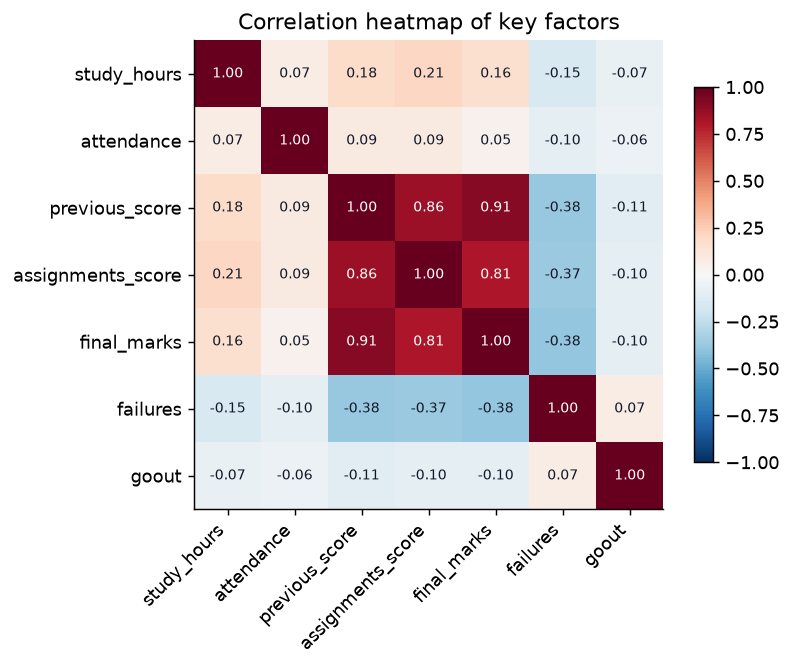

  [chart] t2_study_vs_marks.png


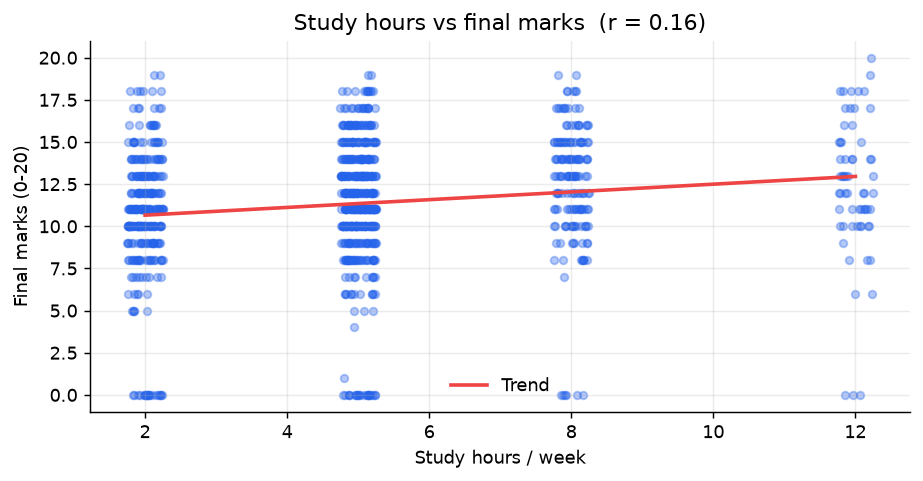

  [chart] t2_attendance.png


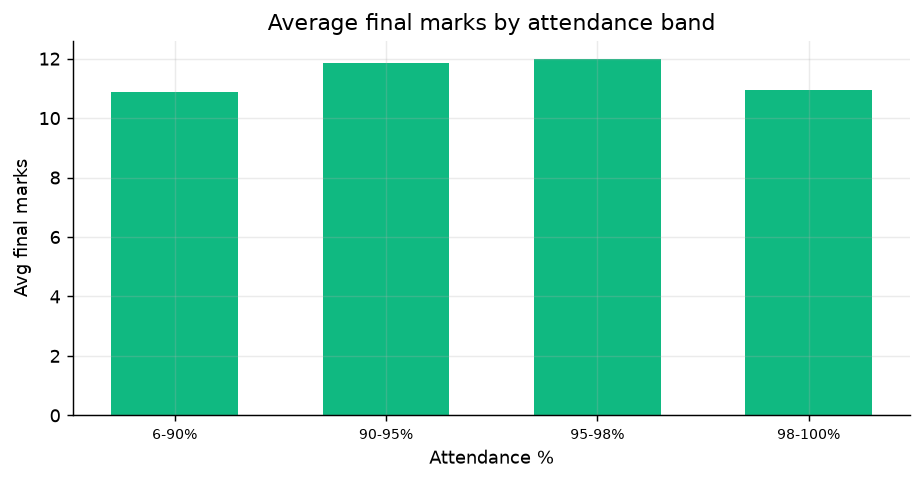

  [chart] t2_dist.png


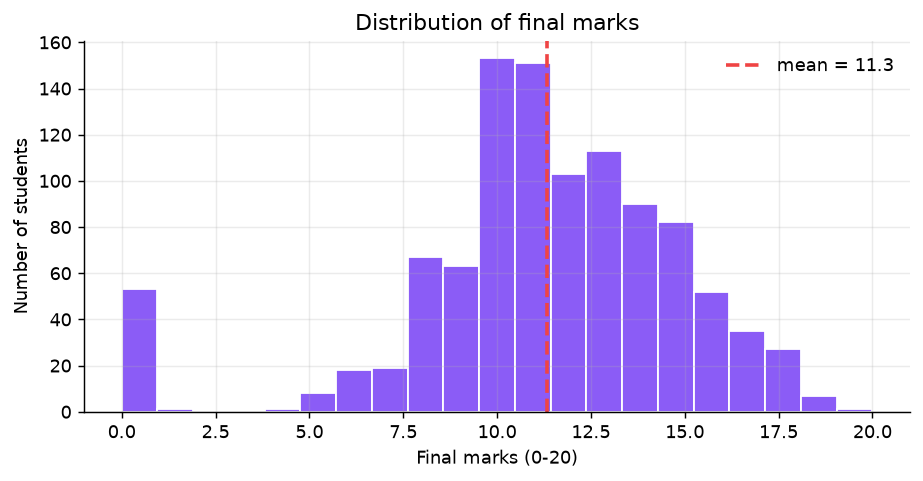

  [chart] t2_featcorr.png


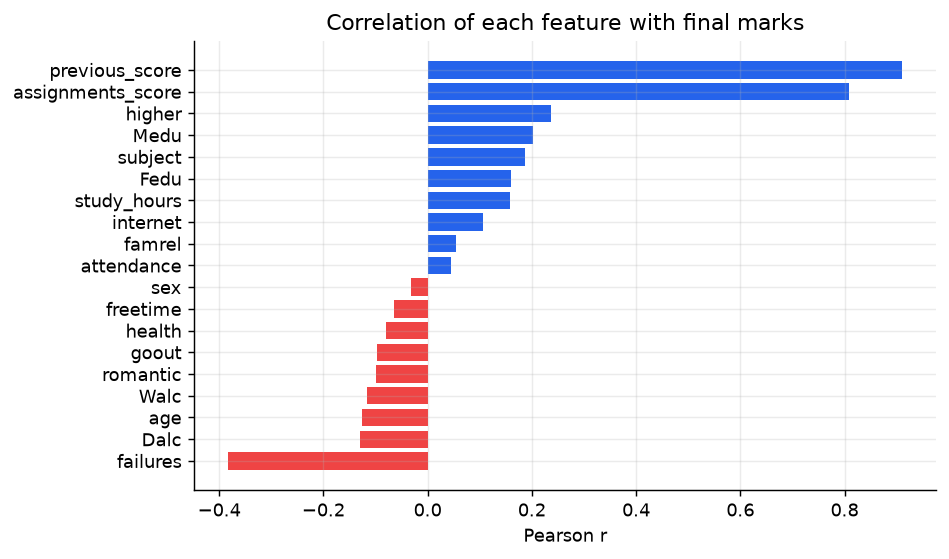

In [6]:
print("STEP 3 - Exploratory data analysis")

# 3a. correlation heatmap
corr = model_df[["study_hours", "attendance", "previous_score",
                 "assignments_score", "final_marks", "failures", "goout"]].corr()
fig, ax = plt.subplots(figsize=(6.4, 5.2))
im = ax.imshow(corr, cmap="RdBu_r", vmin=-1, vmax=1)
ax.set_xticks(range(len(corr))); ax.set_xticklabels(corr.columns, rotation=45, ha="right")
ax.set_yticks(range(len(corr))); ax.set_yticklabels(corr.columns)
for i in range(len(corr)):
    for j in range(len(corr)):
        ax.text(j, i, f"{corr.iloc[i, j]:.2f}", ha="center", va="center",
                color="white" if abs(corr.iloc[i, j]) > 0.55 else "#111827", fontsize=8)
ax.set_title("Correlation heatmap of key factors"); ax.grid(False)
fig.colorbar(im, ax=ax, shrink=0.8)
save(fig, "t2_corr.png")

# 3b. study hours vs final marks
fig, ax = plt.subplots(figsize=(7.2, 3.8))
ax.scatter(df["study_hours"] + np.random.uniform(-0.25, 0.25, len(df)), df["final_marks"],
           alpha=0.35, s=18, color=PALETTE["primary"])
z = np.polyfit(df["study_hours"], df["final_marks"], 1)
xs = np.linspace(df["study_hours"].min(), df["study_hours"].max(), 50)
ax.plot(xs, np.polyval(z, xs), color=PALETTE["danger"], lw=2, label="Trend")
r = df["study_hours"].corr(df["final_marks"])
ax.set_title(f"Study hours vs final marks  (r = {r:.2f})")
ax.set_xlabel("Study hours / week"); ax.set_ylabel("Final marks (0-20)"); ax.legend(frameon=False)
save(fig, "t2_study_vs_marks.png")

# 3c. attendance vs performance (deciles)
df["att_bin"] = pd.qcut(df["attendance"], 5, duplicates="drop")
att = df.groupby("att_bin", observed=True)["final_marks"].mean()
fig, ax = plt.subplots(figsize=(7.2, 3.8))
ax.bar(range(len(att)), att.values, color=PALETTE["green"], width=0.6)
ax.set_xticks(range(len(att)))
ax.set_xticklabels([f"{iv.left:.0f}-{iv.right:.0f}%" for iv in att.index], fontsize=8)
ax.set_title("Average final marks by attendance band")
ax.set_xlabel("Attendance %"); ax.set_ylabel("Avg final marks")
save(fig, "t2_attendance.png")

# 3d. distribution of scores
fig, ax = plt.subplots(figsize=(7.2, 3.8))
ax.hist(df["final_marks"], bins=21, color=PALETTE["purple"], edgecolor="white")
ax.axvline(df["final_marks"].mean(), color=PALETTE["danger"], ls="--", lw=2,
           label=f"mean = {df['final_marks'].mean():.1f}")
ax.set_title("Distribution of final marks")
ax.set_xlabel("Final marks (0-20)"); ax.set_ylabel("Number of students"); ax.legend(frameon=False)
save(fig, "t2_dist.png")

# 3e. correlation strength of every feature vs target
feat_corr = (model_df[FEATURES + ["final_marks"]].corr()["final_marks"]
             .drop("final_marks").sort_values())
fig, ax = plt.subplots(figsize=(7.4, 4.4))
ax.barh(feat_corr.index, feat_corr.values,
        color=[PALETTE["danger"] if v < 0 else PALETTE["primary"] for v in feat_corr.values])
ax.set_title("Correlation of each feature with final marks")
ax.set_xlabel("Pearson r")
save(fig, "t2_featcorr.png")

## 4/5. Models

STEP 4/5 - Model building, training & testing
  Linear Regression  MAE= 0.969  MSE=  2.936  R2= 0.810
  Decision Tree      MAE= 0.991  MSE=  3.307  R2= 0.786


  Random Forest      MAE= 0.901  MSE=  2.609  R2= 0.831
  --> best model by R^2: Random Forest


  [chart] t2_importance.png


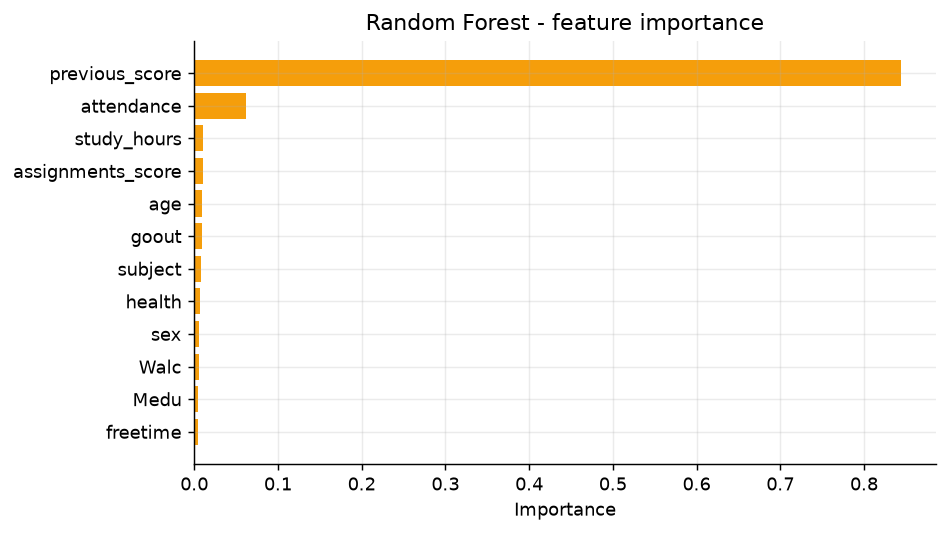

  [chart] t2_avp.png


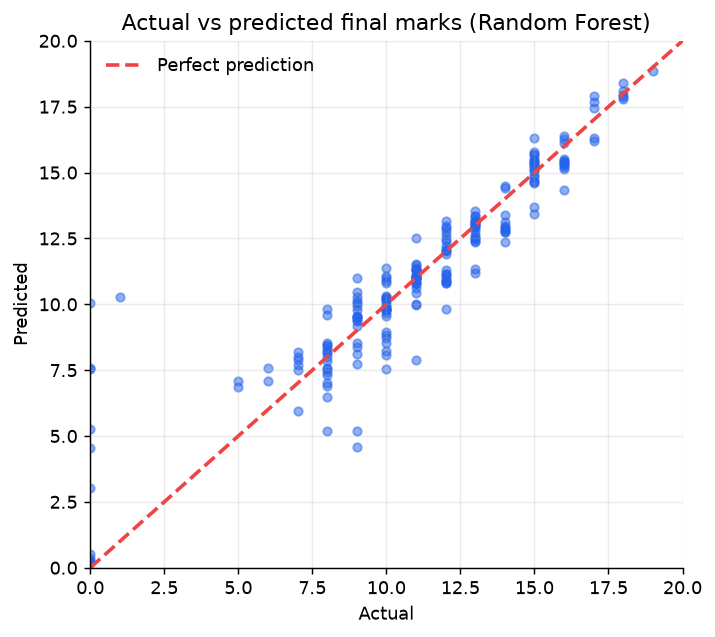

In [7]:
print("STEP 4/5 - Model building, training & testing")
models = {
    "Linear Regression": (LinearRegression(), True),
    "Decision Tree": (DecisionTreeRegressor(max_depth=6, random_state=42), False),
    "Random Forest": (RandomForestRegressor(n_estimators=400, max_depth=12,
                                            min_samples_leaf=2, random_state=42, n_jobs=-1), False),
}
results, preds = {}, {}
for name, (mdl, needs_scale) in models.items():
    Xtr = X_tr_s if needs_scale else X_tr
    Xte = X_te_s if needs_scale else X_te
    mdl.fit(Xtr, y_tr)
    p = mdl.predict(Xte)
    preds[name] = p
    mae = mean_absolute_error(y_te, p)
    mse = mean_squared_error(y_te, p)
    r2 = r2_score(y_te, p)
    results[name] = {"MAE": round(mae, 3), "MSE": round(mse, 3), "R2": round(r2, 4)}
    print(f"  {name:18s} MAE={mae:6.3f}  MSE={mse:7.3f}  R2={r2:6.3f}")

best_model = max(results, key=lambda k: results[k]["R2"])
print(f"  --> best model by R^2: {best_model}")

# feature importance from Random Forest
rf = models["Random Forest"][0]
imp = pd.Series(rf.feature_importances_, index=FEATURES).sort_values().tail(12)
fig, ax = plt.subplots(figsize=(7.4, 4.2))
ax.barh(imp.index, imp.values, color=PALETTE["accent"])
ax.set_title("Random Forest - feature importance")
ax.set_xlabel("Importance")
save(fig, "t2_importance.png")

# actual vs predicted
fig, ax = plt.subplots(figsize=(5.6, 5.0))
ax.scatter(y_te, preds[best_model], alpha=0.5, s=22, color=PALETTE["primary"])
lim = [0, 20]; ax.plot(lim, lim, color=PALETTE["danger"], ls="--", lw=2, label="Perfect prediction")
ax.set_xlim(lim); ax.set_ylim(lim)
ax.set_title(f"Actual vs predicted final marks ({best_model})")
ax.set_xlabel("Actual"); ax.set_ylabel("Predicted"); ax.legend(frameon=False)
save(fig, "t2_avp.png")

## 6. Eval + Save

In [8]:
print("STEP 6 - Evaluation & artifacts")
metrics = {
    "task": "Student Performance Predictor",
    "dataset": "UCI Student Performance (Cortez & Silva) - Math + Portuguese",
    "students": int(len(df)),
    "train": int(len(X_tr)), "test": int(len(X_te)),
    "features": FEATURES,
    "models": results, "best_model": best_model,
    "target": "final_marks (G3, 0-20 scale)",
    "mean_final_marks": round(float(df["final_marks"].mean()), 2),
    "corr_study_hours_marks": round(float(r), 3),
}
with open(os.path.join(ART, "metrics.json"), "w") as f:
    json.dump(metrics, f, indent=2)
cmp = pd.DataFrame({"actual": y_te.values, "predicted": np.round(preds[best_model], 2)})
cmp.to_csv(os.path.join(ART, "predictions.csv"), index=False)

# export a small sample for the web demo + model coefficients for a live predictor
sample = df[["subject", "study_hours", "attendance", "previous_score",
             "assignments_score", "final_marks"]].sample(200, random_state=1)
sample.to_csv(os.path.join(ART, "sample_students.csv"), index=False)

# fit a compact linear model on the 4 headline features for the interactive UI
simple_X = df[["study_hours", "attendance", "previous_score", "assignments_score"]]
simple_m = LinearRegression().fit(simple_X, df["final_marks"])
simple_metrics = {
    "coef": [round(float(c), 4) for c in simple_m.coef_],
    "intercept": round(float(simple_m.intercept_), 4),
    "r2": round(float(r2_score(df["final_marks"], simple_m.predict(simple_X))), 4),
    "mae": round(float(mean_absolute_error(df["final_marks"], simple_m.predict(simple_X))), 3),
}
with open(os.path.join(ART, "simple_model.json"), "w") as f:
    json.dump(simple_metrics, f, indent=2)

web_payload = {
    "metrics": metrics, "simple_model": simple_metrics,
    "corr": {"labels": corr.columns.tolist(),
             "values": [[round(float(v), 2) for v in row] for row in corr.values]},
    "study_vs_marks": {"x": df["study_hours"].tolist(), "y": df["final_marks"].tolist(), "r": round(float(r), 3)},
    "attendance": {"labels": [f"{iv.left:.0f}-{iv.right:.0f}" for iv in att.index],
                   "values": att.round(2).tolist()},
    "dist": {"values": df["final_marks"].tolist(), "mean": round(float(df["final_marks"].mean()), 2)},
    "featcorr": {"labels": feat_corr.index.tolist(), "values": feat_corr.round(3).tolist()},
    "importance": {"labels": imp.index.tolist(), "values": imp.round(4).tolist()},
    "avp": {"actual": y_te.tolist(), "predicted": np.round(preds[best_model], 2).tolist()},
    "sample": sample.to_dict(orient="records"),
}
with open(os.path.join(WEB, "t2_data.json"), "w") as f:
    json.dump(web_payload, f)

print("\n  RESULTS")
for k, v in results.items():
    print(f"    {k:18s} MAE={v['MAE']:>7}  MSE={v['MSE']:>8}  R2={v['R2']:>7}")
print(f"  best={best_model} | corr(study hours, marks)={r:.3f}")
print("TASK 2 COMPLETE")

STEP 6 - Evaluation & artifacts

  RESULTS
    Linear Regression  MAE=  0.969  MSE=   2.936  R2= 0.8101
    Decision Tree      MAE=  0.991  MSE=   3.307  R2= 0.7861
    Random Forest      MAE=  0.901  MSE=   2.609  R2= 0.8312
  best=Random Forest | corr(study hours, marks)=0.158
TASK 2 COMPLETE
